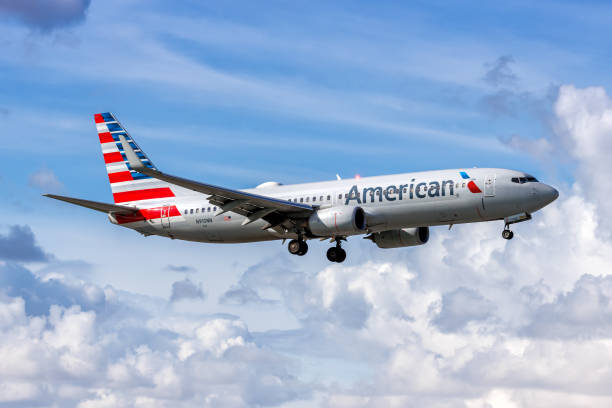


#**Predicción de la satisfacción del pasajero basada en la calidad del servicio en la aerolínea**

**Nombre:** Cristian Mauricio Tello Diaz

In [2]:
#@title 1. MONTAR EL DRIVE { display-mode: "form" }
import os
from google.colab import drive
drive.mount('/content/drive')
os.chdir('/content/drive/My Drive/Machine learning/Proyecto ')
print(os.getcwd())

Mounted at /content/drive
/content/drive/My Drive/Machine learning/Proyecto 


In [3]:
#@title 1. Cargar base de datos { display-mode: "form" }
import pandas as pd
# Cargamos el La base de datos
df = pd.read_csv('data Airline.csv')

# Validamos que los datos se lean correctamente mostrando las primeras filas
df.head(11)

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True
5,Female,Loyal Customer,26,Personal Travel,Eco,1180,3,4,2,1,...,1,1,3,4,4,4,1,0,0.0,False
6,Male,Loyal Customer,47,Personal Travel,Eco,1276,2,4,2,3,...,2,2,3,3,4,3,2,9,23.0,False
7,Female,Loyal Customer,52,Business travel,Business,2035,4,3,4,4,...,5,5,5,5,5,4,4,4,0.0,True
8,Female,Loyal Customer,41,Business travel,Business,853,1,2,2,2,...,3,1,1,2,1,4,2,0,0.0,False
9,Male,disloyal Customer,20,Business travel,Eco,1061,3,3,3,4,...,3,2,2,3,4,4,2,0,0.0,False


In [4]:
print(df.columns.tolist())

['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']


In [5]:
df.describe()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129880.000000,129487.000000
mean,39.427957,1190.316392,2.728696,3.057599,2.756876,2.976925,3.204774,3.252633,3.441361,3.358077,3.383023,3.350878,3.632114,3.306267,3.286326,14.713713,15.091129
std,15.119360,997.452477,1.329340,1.526741,1.401740,1.278520,1.329933,1.350719,1.319289,1.334049,1.287099,1.316252,1.180025,1.266185,1.313682,38.071126,38.465650
min,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,40.000000,844.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,0.000000,0.000000
75%,51.000000,1744.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,12.000000,13.000000
max,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [6]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [7]:
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    1298

In [9]:
#@title 1. CAMBIO DE CATEGORÍA A NÚMERO { display-mode: "form" }
# 1. Columna: Gender
df['Gender'] = df['Gender'].map({'Male': 0, 'Female': 1})

# 2. Columna: Customer Type
df['Customer Type'] = df['Customer Type'].map({'disloyal Customer': 0, 'Loyal Customer': 1})

# 3. Columna: Type of Travel
df['Type of Travel'] = df['Type of Travel'].map({'Personal Travel': 0, 'Business travel': 1})

# 4. Columna: Class (Como tiene 3 niveles, asignamos 0, 1 y 2)
df['Class'] = df['Class'].map({'Eco': 0, 'Eco Plus': 1, 'Business': 2})

# 5. Columna: satisfaction (Para asegurar que sea 0 o 1 si venía como texto)
df['satisfaction'] = df['satisfaction'].map({'False': 0, 'True': 1, False: 0, True: 1})

# Verificamos que ahora todo el dataset sea numérico
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,1,13,0,1,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,0
1,0,0,25,1,2,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,0
2,1,1,26,1,2,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,1
3,1,1,25,1,2,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,0
4,0,1,61,1,2,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,1


In [10]:
df.head(11)

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,1,13,0,1,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,0
1,0,0,25,1,2,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,0
2,1,1,26,1,2,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,1
3,1,1,25,1,2,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,0
4,0,1,61,1,2,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,1
5,1,1,26,0,0,1180,3,4,2,1,...,1,1,3,4,4,4,1,0,0.0,0
6,0,1,47,0,0,1276,2,4,2,3,...,2,2,3,3,4,3,2,9,23.0,0
7,1,1,52,1,2,2035,4,3,4,4,...,5,5,5,5,5,4,4,4,0.0,1
8,1,1,41,1,2,853,1,2,2,2,...,3,1,1,2,1,4,2,0,0.0,0
9,0,0,20,1,0,1061,3,3,3,4,...,3,2,2,3,4,4,2,0,0.0,0


In [11]:
#@title 1. IQR { display-mode: "form" }

# Recorremos todas las columnas deL dataset automáticamente
for colum in df.columns:

    # 1. Calcular Q1 (25%) y Q3 (75%) para la columna actual
    Q1 = df[colum].quantile(0.25)
    Q3 = df[colum].quantile(0.75)

    # 2. Calcular el IQR
    IQR = Q3 - Q1

    # 3. Definir límites inferior y superior
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # 4. Imprimir los resultados de forma ordenada para cada columna
    print(f"📊 Columna: {colum}")

    print("   limite inferior:", limite_inferior)
    print("   limite superior:", limite_superior)
    print("-" * 40) # Esto es solo una línea divisoria para que se vea ordenado

📊 Columna: Gender
   limite inferior: -1.5
   limite superior: 2.5
----------------------------------------
📊 Columna: Customer Type
   limite inferior: 1.0
   limite superior: 1.0
----------------------------------------
📊 Columna: Age
   limite inferior: -9.0
   limite superior: 87.0
----------------------------------------
📊 Columna: Type of Travel
   limite inferior: -1.5
   limite superior: 2.5
----------------------------------------
📊 Columna: Class
   limite inferior: -3.0
   limite superior: 5.0
----------------------------------------
📊 Columna: Flight Distance
   limite inferior: -1581.0
   limite superior: 3739.0
----------------------------------------
📊 Columna: Inflight wifi service
   limite inferior: -1.0
   limite superior: 7.0
----------------------------------------
📊 Columna: Departure/Arrival time convenient
   limite inferior: -1.0
   limite superior: 7.0
----------------------------------------
📊 Columna: Ease of Online booking
   limite inferior: -1.0
   limite

In [12]:
print(df['Gender'].value_counts())

Gender
1    65899
0    63981
Name: count, dtype: int64


#**Graficos Pie**

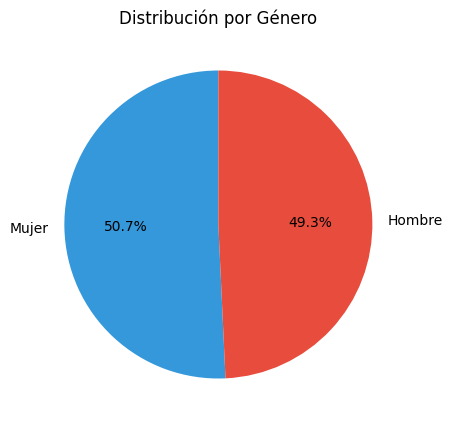

In [13]:
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. GRÁFICO DE PASTEL: Gender (Género)
# ----------------------------------------------------
plt.figure(figsize=(5, 5))
# Contamos cuántos hay de cada número y les ponemos su nombre real
df['Gender'].value_counts().plot(kind='pie',
                                 labels=['Mujer', 'Hombre'],
                                 autopct='%1.1f%%',
                                 startangle=90,
                                 colors=['#3498db', '#e74c3c'])
plt.title('Distribución por Género')
plt.ylabel('') # Esto quita un texto automático molesto al lado del gráfico
plt.show()

print("\n" + "="*50 + "\n")

In [14]:
print(df['Customer Type'].value_counts())

Customer Type
1    106100
0     23780
Name: count, dtype: int64


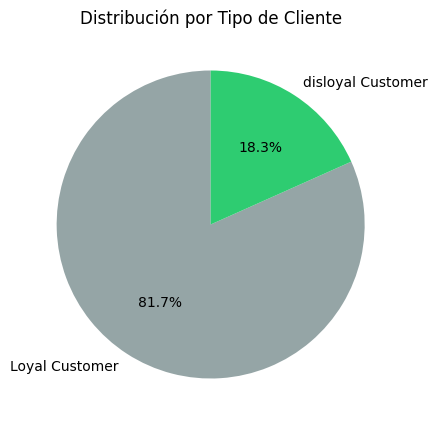

In [15]:
# ----------------------------------------------------
# 2. GRÁFICO DE PASTEL: Customer Type (Tipo de Cliente)
# ----------------------------------------------------
plt.figure(figsize=(5, 5))
df['Customer Type'].value_counts().plot(kind='pie',
                                        labels=['Loyal Customer', 'disloyal Customer'],
                                        autopct='%1.1f%%',
                                        startangle=90,
                                        colors=['#95a5a6', '#2ecc71'])
plt.title('Distribución por Tipo de Cliente')
plt.ylabel('')
plt.show()

print("\n" + "="*50 + "\n")

In [16]:
print(df['Type of Travel'].value_counts())

Type of Travel
1    89693
0    40187
Name: count, dtype: int64


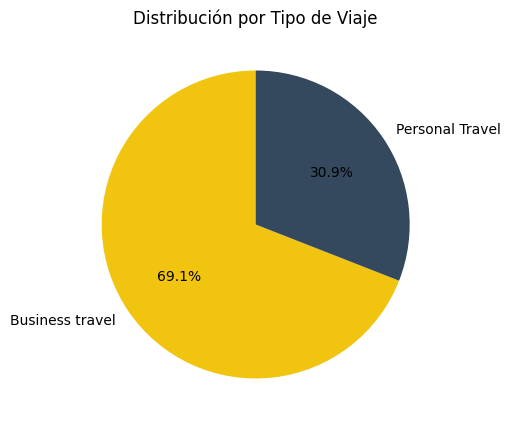

In [17]:
# ----------------------------------------------------
# 3. GRÁFICO DE PASTEL: Type of Travel (Tipo de Viaje)
# ----------------------------------------------------
plt.figure(figsize=(5, 5))
df['Type of Travel'].value_counts().plot(kind='pie',
                                         labels=['Business travel', 'Personal Travel'],
                                         autopct='%1.1f%%',
                                         startangle=90,
                                         colors=['#f1c40f', '#34495e'])
plt.title('Distribución por Tipo de Viaje')
plt.ylabel('')
plt.show()

print("\n" + "="*50 + "\n")

In [18]:
print(df['Class'].value_counts())

Class
2    62160
0    58309
1     9411
Name: count, dtype: int64


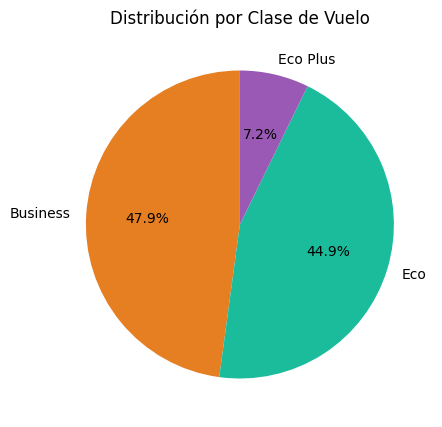

In [19]:
# ----------------------------------------------------
# 4. GRÁFICO DE PASTEL: Class (Clase de Vuelo)
# ----------------------------------------------------
plt.figure(figsize=(5, 5))
df['Class'].value_counts().plot(kind='pie',
                                labels=['Business', 'Eco', 'Eco Plus'],
                                autopct='%1.1f%%',
                                startangle=90,
                                colors=['#e67e22', '#1abc9c', '#9b59b6'])
plt.title('Distribución por Clase de Vuelo')
plt.ylabel('')
plt.show()


In [20]:
print(df['satisfaction'].value_counts())

satisfaction
0    73452
1    56428
Name: count, dtype: int64


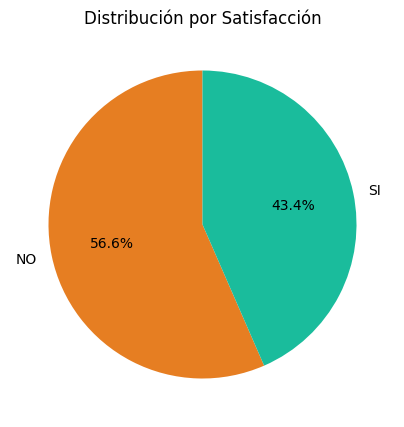

In [21]:

# ----------------------------------------------------
# 4. GRÁFICO DE PASTEL: Class (Satisfacción)
# ----------------------------------------------------
plt.figure(figsize=(5, 5))
df['satisfaction'].value_counts().plot(kind='pie',
                                labels=['NO', 'SI'],
                                autopct='%1.1f%%',
                                startangle=90,
                                colors=['#e67e22', '#1abc9c', '#9b59b6'])
plt.title('Distribución por Satisfacción')
plt.ylabel('')
plt.show()


#**Graficos Plot**

In [22]:
# Contamos cuántos pasajeros hay por cada edad
conteo_edades = df['Age'].value_counts()

# Imprimimos el resultado de forma ordenada y bonita
print("CONTEO DE PASAJEROS POR EDAD:")
print("---------------------------------")
for edad, cantidad in conteo_edades.items():
    print(f"Edad {int(edad)} años: {cantidad} pasajeros")

CONTEO DE PASAJEROS POR EDAD:
---------------------------------
Edad 39 años: 3692 pasajeros
Edad 25 años: 3511 pasajeros
Edad 40 años: 3209 pasajeros
Edad 44 años: 3104 pasajeros
Edad 41 años: 3089 pasajeros
Edad 42 años: 3017 pasajeros
Edad 43 años: 2941 pasajeros
Edad 45 años: 2939 pasajeros
Edad 23 años: 2935 pasajeros
Edad 22 años: 2931 pasajeros
Edad 48 años: 2889 pasajeros
Edad 47 años: 2888 pasajeros
Edad 37 años: 2881 pasajeros
Edad 38 años: 2878 pasajeros
Edad 36 años: 2867 pasajeros
Edad 24 años: 2836 pasajeros
Edad 26 años: 2822 pasajeros
Edad 49 años: 2789 pasajeros
Edad 27 años: 2781 pasajeros
Edad 46 años: 2771 pasajeros
Edad 51 años: 2611 pasajeros
Edad 52 años: 2599 pasajeros
Edad 50 años: 2579 pasajeros
Edad 30 años: 2521 pasajeros
Edad 29 años: 2435 pasajeros
Edad 35 años: 2398 pasajeros
Edad 54 años: 2397 pasajeros
Edad 53 años: 2377 pasajeros
Edad 55 años: 2339 pasajeros
Edad 33 años: 2334 pasajeros
Edad 57 años: 2334 pasajeros
Edad 56 años: 2310 pasajeros
Edad 58 

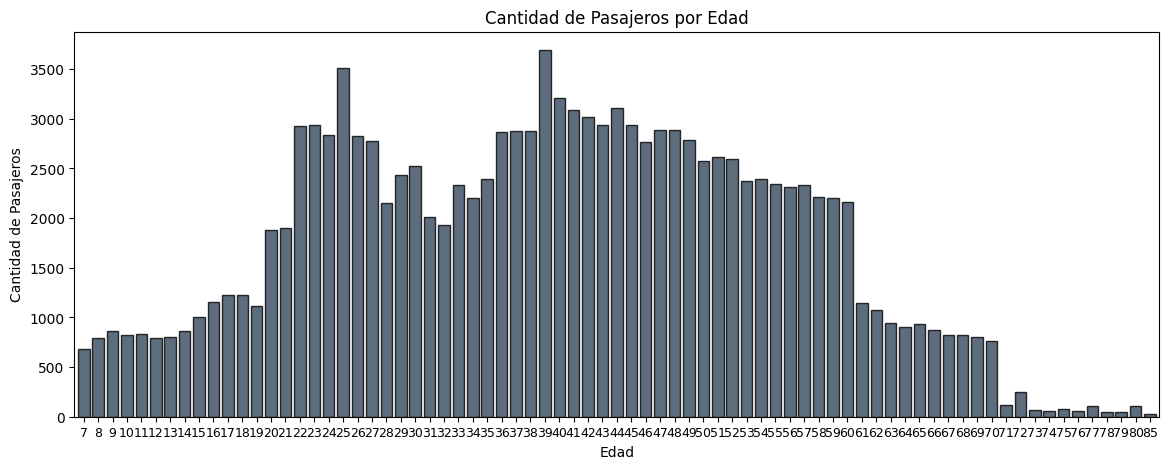

In [23]:
# 1. Contamos cuántos pasajeros hay por edad
conteo_ordenado_edad = df['Age'].value_counts().sort_index()

# 2. Creamos el gráfico de barras con el eje X ordenado cronológicamente
plt.figure(figsize=(14, 5))
conteo_ordenado_edad.plot(kind='bar', color='#34495e', alpha=0.8, edgecolor='black', width=0.8)

# Personalizamos
plt.title('Cantidad de Pasajeros por Edad')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Pasajeros')

# Esto hace que las etiquetas del eje X se lean de forma horizontal y ordenada
plt.xticks(rotation=0, fontsize=9)


plt.show()



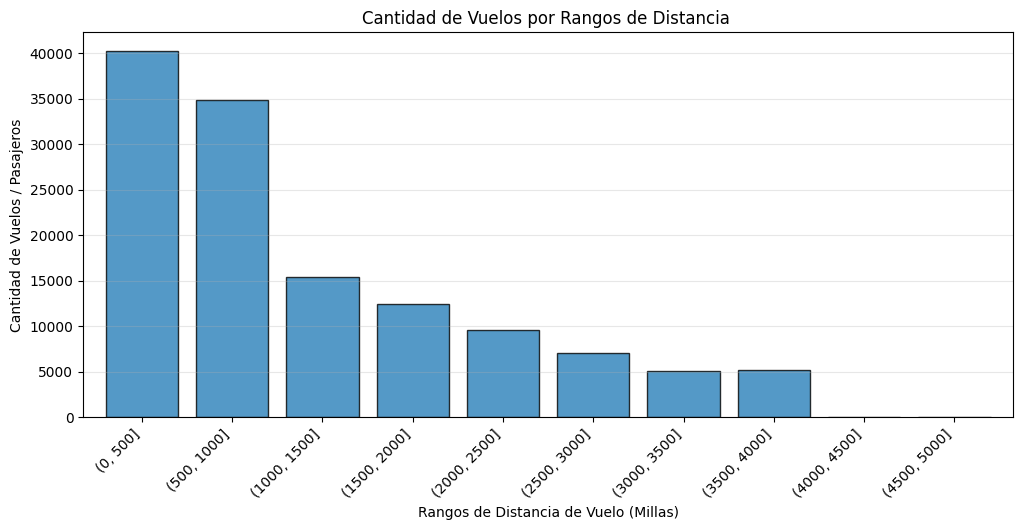

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Agrupamos las distancias en rangos ordenados de 500 en 500 millas
# (El código calcula automáticamente cuántos vuelos caen en cada rango)
distancia_agrupada = pd.cut(df['Flight Distance'],
                            bins=[0, 500, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000]).value_counts().sort_index()

# 2. Creamos el gráfico de barras por rangos usando estrictamente .plot()
plt.figure(figsize=(12, 5))
distancia_agrupada.plot(kind='bar', color='#2980b9', alpha=0.8, edgecolor='black', width=0.8)

# Personalizamos las etiquetas para que tu profesor lo entienda a la perfección
plt.title('Cantidad de Vuelos por Rangos de Distancia ')
plt.xlabel('Rangos de Distancia de Vuelo (Millas)')
plt.ylabel('Cantidad de Vuelos / Pasajeros')

# Rotamos las etiquetas un poco para que se lean de forma cómoda y limpia
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.show()


In [25]:
conteo_wifi = df['Inflight wifi service'].value_counts().sort_index()
print(conteo_wifi)

Inflight wifi service
0     3916
1    22328
2    32320
3    32185
4    24775
5    14356
Name: count, dtype: int64


13


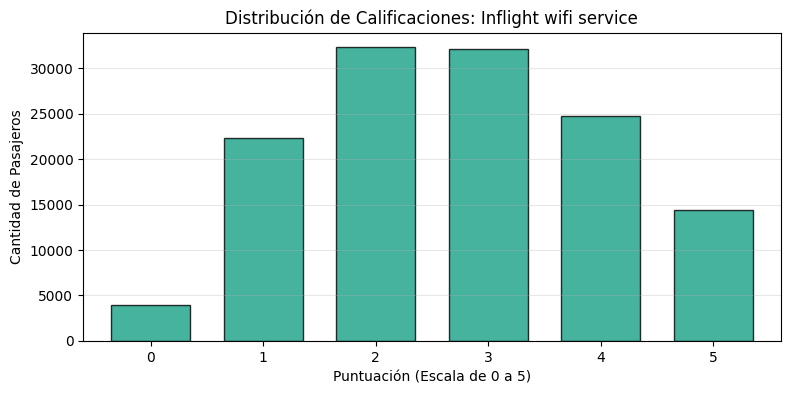


----------------------------------------------------------------------



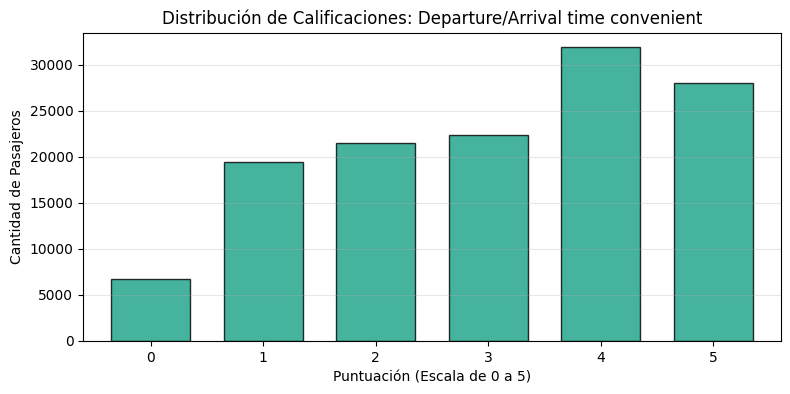


----------------------------------------------------------------------



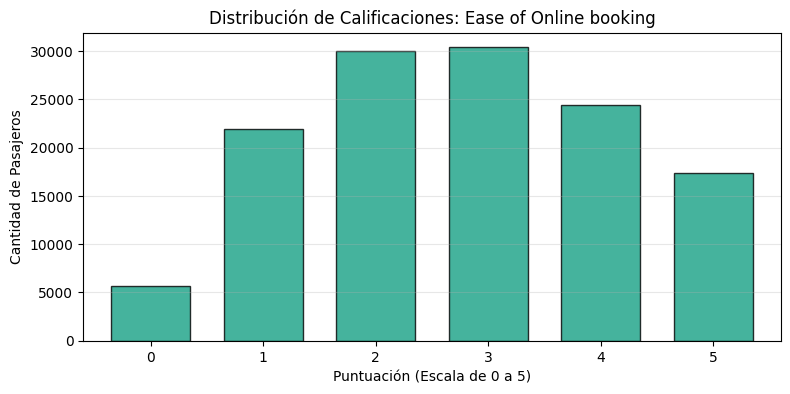


----------------------------------------------------------------------



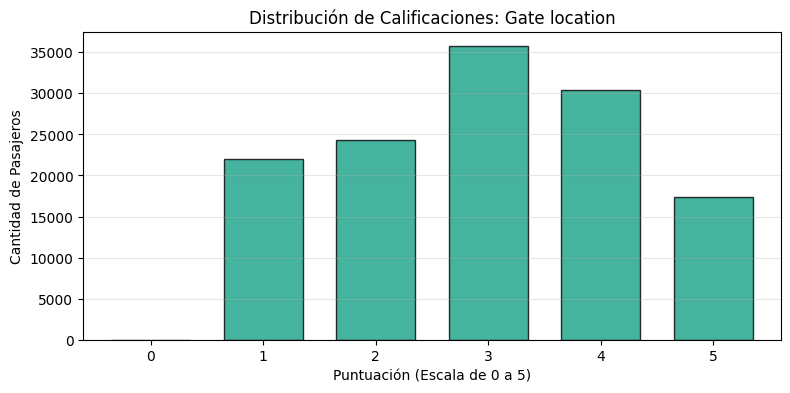


----------------------------------------------------------------------



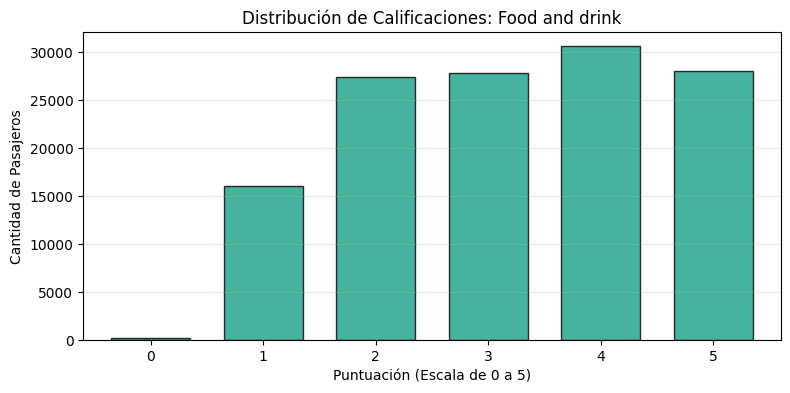


----------------------------------------------------------------------



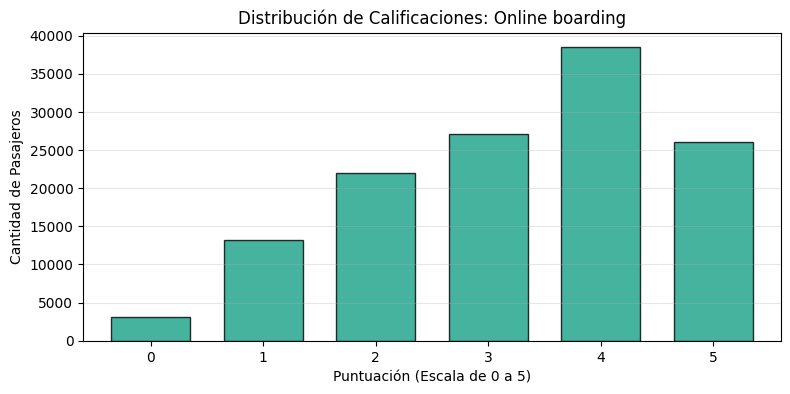


----------------------------------------------------------------------



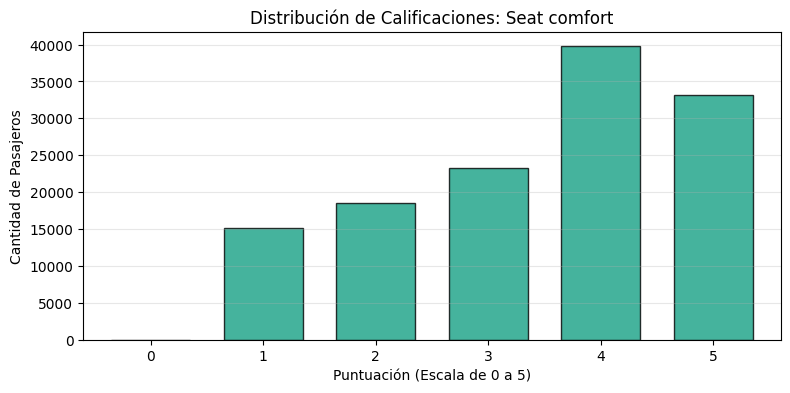


----------------------------------------------------------------------



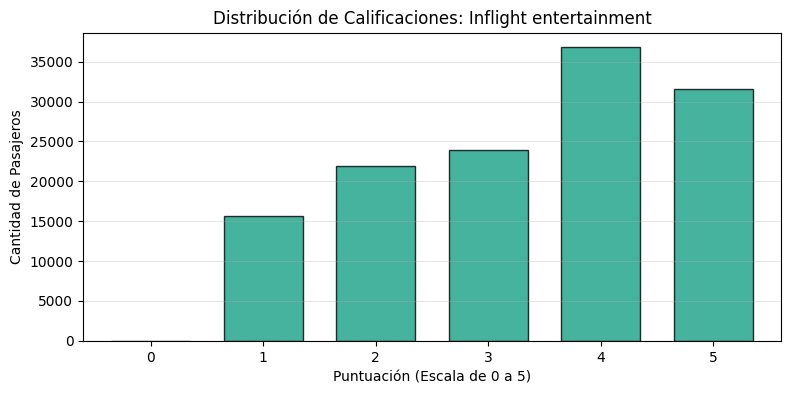


----------------------------------------------------------------------



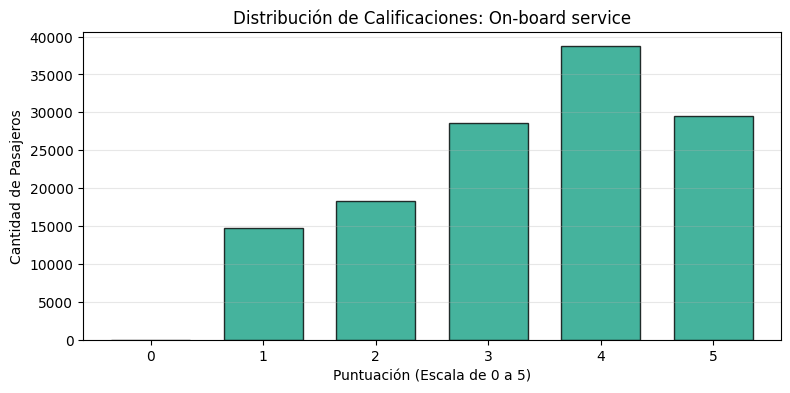


----------------------------------------------------------------------



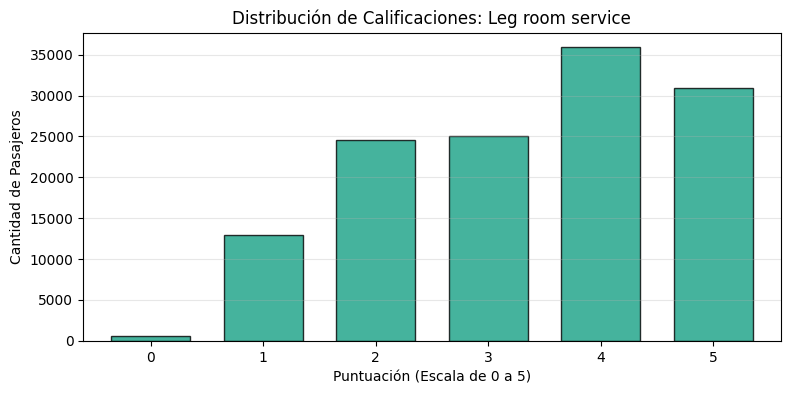


----------------------------------------------------------------------



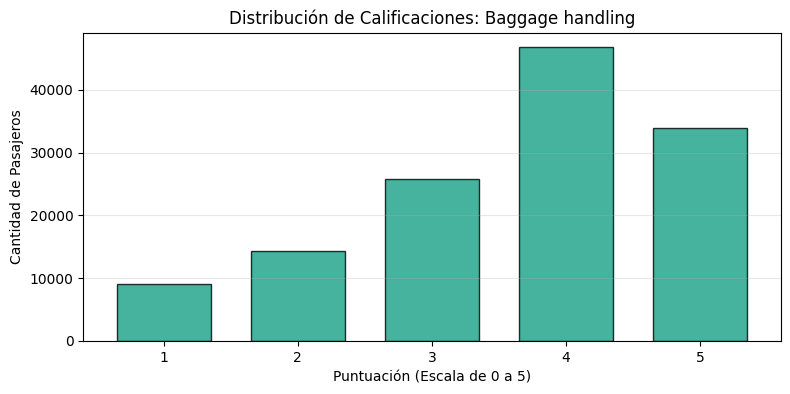


----------------------------------------------------------------------



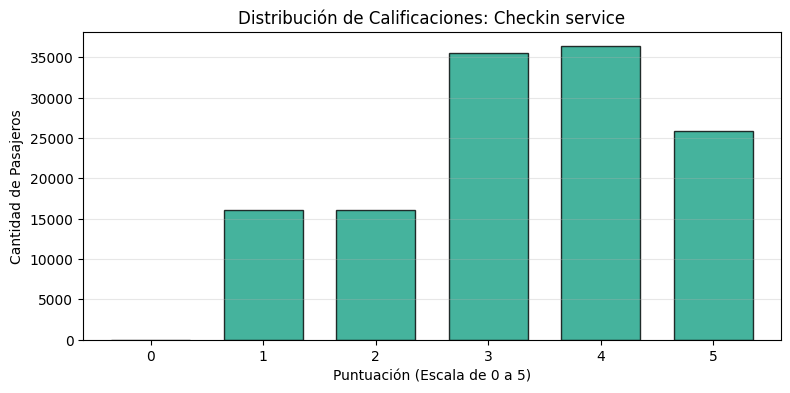


----------------------------------------------------------------------



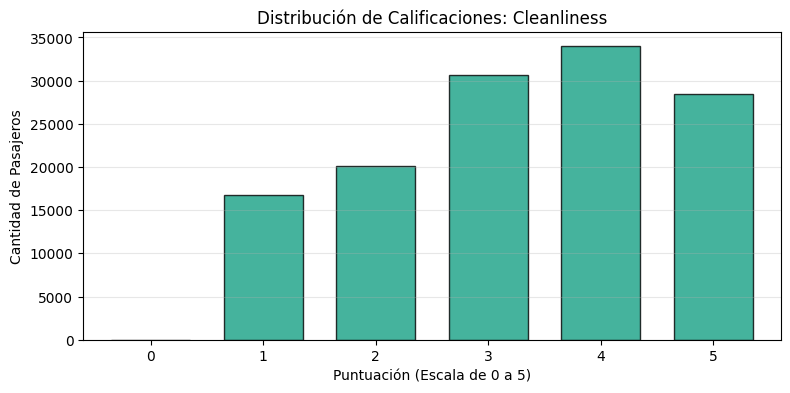


----------------------------------------------------------------------



In [26]:
# 1. servicios
columnas_servicio = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

# 2. cantidad de servicios
print(len(columnas_servicio))

# 3. bucle for para imprimir cada servicio con sus valores correspondientes
for col in columnas_servicio:
    plt.figure(figsize=(9, 4))

    # Conteo de calificaciones y ordenamos desde 0-5
    conteo_servicio = df[col].value_counts().sort_index()

    # Dibujamos el gráfico usando .plot()
    conteo_servicio.plot(kind='bar', color='#16a085', alpha=0.8, edgecolor='black', width=0.7)

    # Personalizamos los títulos y etiquetas dinámicamente según la columna actual
    plt.title(f'Distribución de Calificaciones: {col}')
    plt.xlabel('Puntuación (Escala de 0 a 5)')
    plt.ylabel('Cantidad de Pasajeros')
    plt.xticks(rotation=0)
    plt.grid(axis='y', alpha=0.3)

    # Mostramos el gráfico actual antes de pasar al siguiente en la lista
    plt.show()
    print("\n" + "-"*70 + "\n") # Línea de separacion





#**Parte 2: Modelos de clasificación**

Se reutiliza el dataframe `df` ya cargado y codificado en las celdas anteriores. Flujo: limpieza → partición 80/20 → DecisionTree, RandomForest y SVM (curvas por hiperparámetro) → validación cruzada → perceptrón multicapa → comparación con barplot.

In [27]:
#@title 2. LIMPIEZA DE DATOS { display-mode: "form" }
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Nulos y duplicados
nulos = df.isna().sum()
print("Columnas con nulos:")
print(nulos[nulos > 0])
print("Filas duplicadas:", df.duplicated().sum())

# 2. 'Arrival Delay in Minutes' tiene nulos: se imputan con la mediana
#    (la distribución es muy sesgada y la mediana no se afecta por los valores extremos)
mediana = df['Arrival Delay in Minutes'].median()
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(mediana)

# 3. La variable objetivo debe quedar como entero 0/1
df['satisfaction'] = df['satisfaction'].astype(int)

# 4. Verificación final: sin nulos y todo numérico
print("\nNulos restantes:", df.isna().sum().sum())
print("Columnas no numéricas:", df.select_dtypes(exclude='number').columns.tolist())
print("Tamaño final:", df.shape)

Columnas con nulos:
Arrival Delay in Minutes    393
dtype: int64
Filas duplicadas: 0

Nulos restantes: 0
Columnas no numéricas: []
Tamaño final: (129880, 22)


**Nota sobre outliers:** los valores extremos detectados con IQR (retrasos y distancia de vuelo) son datos reales, no errores, así que se conservan. Los árboles y el random forest no se ven afectados por ellos; para SVM y redes neuronales se estandariza (paso siguiente).

In [28]:
#@title 3. PARTICIÓN 80/20, ESCALADO Y MÉTRICAS { display-mode: "form" }
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

X = df.drop(columns='satisfaction').values
y = df['satisfaction'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21, stratify=y)

# El escalado se ajusta SOLO con train
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("train:", X_train.shape, " test:", X_test.shape)
print("proporción de satisfechos train / test: %.3f / %.3f" % (y_train.mean(), y_test.mean()))


def tpr(est, X, y):
    p = est.predict(X)
    return np.mean(p[y == 1] == y[y == 1])

def tnr(est, X, y):
    p = est.predict(X)
    return np.mean(p[y == 0] == y[y == 0])

resultados = {}   # desempeño de cada modelo sobre test

def evaluar(nombre, est, X, y):
    acc = accuracy_score(y, est.predict(X))
    resultados[nombre] = {'accuracy': acc, 'tpr': tpr(est, X, y), 'tnr': tnr(est, X, y)}
    print("%s -> accuracy %.4f | tpr %.4f | tnr %.4f" % (nombre, acc, resultados[nombre]['tpr'], resultados[nombre]['tnr']))

train: (103904, 21)  test: (25976, 21)
proporción de satisfechos train / test: 0.434 / 0.434


In [29]:
#@title 4. FUNCIÓN PARA CURVAS DE APRENDIZAJE POR HIPERPARÁMETRO { display-mode: "form" }
from sklearn.model_selection import validation_curve

def curva_hiperparametro(est, X, y, param, valores, cv=3, titulo=''):
    """Para cada valor del hiperparámetro calcula accuracy en train y en validación (CV) y grafica ambas.
    Devuelve el valor con mejor accuracy de validación (la partición de test no se usa aquí)."""
    tr, va = validation_curve(est, X, y, param_name=param, param_range=valores,
                              cv=cv, scoring='accuracy', n_jobs=-1)
    tr_m, va_m = tr.mean(axis=1), va.mean(axis=1)
    mejor = valores[int(np.argmax(va_m))]

    plt.figure(figsize=(8, 4.5))
    plt.plot(valores, tr_m, 'o-', label='Train')
    plt.plot(valores, va_m, 's-', label='Validación (CV)')
    plt.plot(mejor, va_m.max(), '*', color='red', markersize=16, label='Mejor: %s' % mejor)
    plt.title(titulo)
    plt.xlabel(param)
    plt.ylabel('Accuracy')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()
    return mejor

#**Decision Tree** — curva para `max_depth`

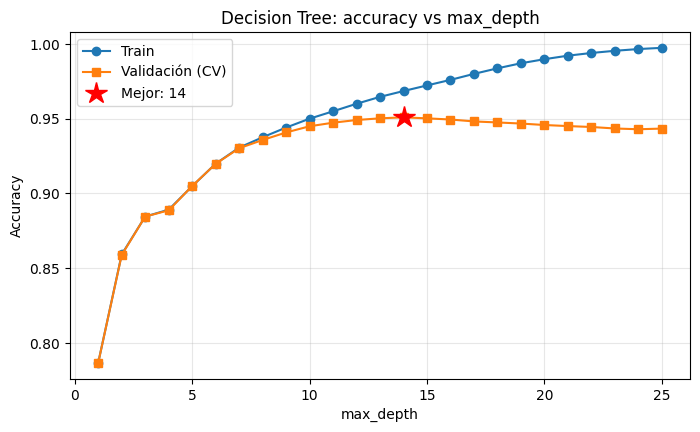

Mejor max_depth: 14
DT -> accuracy 0.9534 | tpr 0.9376 | tnr 0.9655


In [30]:
#@title 5. DECISION TREE { display-mode: "form" }
from sklearn.tree import DecisionTreeClassifier

profundidades = list(range(1, 26))
mejor_prof = curva_hiperparametro(DecisionTreeClassifier(random_state=21), X_train, y_train,
                                  'max_depth', profundidades, cv=5,
                                  titulo='Decision Tree: accuracy vs max_depth')
print("Mejor max_depth:", mejor_prof)

dt = DecisionTreeClassifier(max_depth=mejor_prof, random_state=21).fit(X_train, y_train)
evaluar('DT', dt, X_test, y_test)

#**Random Forest** — curva para `n_estimators`

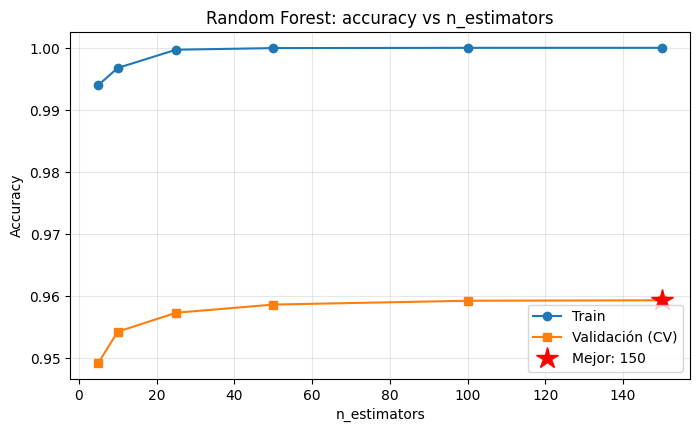

Mejor n_estimators: 150
RF -> accuracy 0.9612 | tpr 0.9383 | tnr 0.9787


In [31]:
#@title 6. RANDOM FOREST { display-mode: "form" }
from sklearn.ensemble import RandomForestClassifier

n_arboles = [5, 10, 25, 50, 100, 150]
mejor_n = curva_hiperparametro(RandomForestClassifier(random_state=21), X_train, y_train,
                               'n_estimators', n_arboles, cv=3,
                               titulo='Random Forest: accuracy vs n_estimators')
print("Mejor n_estimators:", mejor_n)

rf = RandomForestClassifier(n_estimators=mejor_n, random_state=21, n_jobs=-1).fit(X_train, y_train)
evaluar('RF', rf, X_test, y_test)

#**SVM** — curva para `kernel` (linear, poly, rbf)

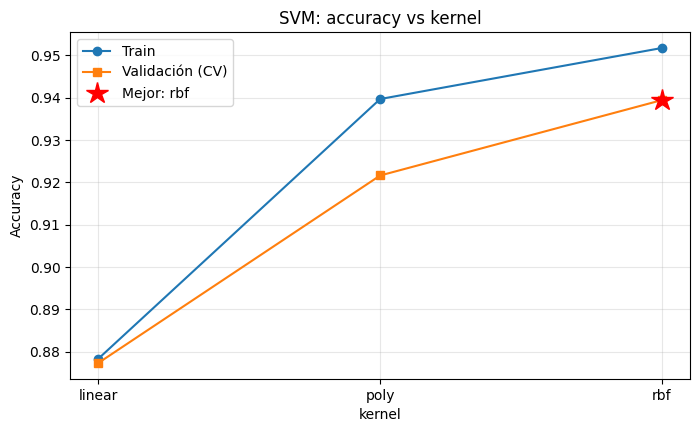

Mejor kernel: rbf
SVM -> accuracy 0.9440 | tpr 0.9211 | tnr 0.9616


In [32]:
#@title 7. SVM { display-mode: "form" }
from sklearn.svm import SVC

# La SVM escala aprox. O(n²): se usa una submuestra estratificada de train para que corra en tiempo razonable.
N_SVM = min(20000, int(len(X_train_s) * 0.8))   # súbalo si quiere usar más datos (tarda más)
X_svm, _, y_svm, _ = train_test_split(X_train_s, y_train, train_size=N_SVM, random_state=21, stratify=y_train)

mejor_kernel = curva_hiperparametro(SVC(), X_svm, y_svm, 'kernel', ['linear', 'poly', 'rbf'], cv=3,
                                    titulo='SVM: accuracy vs kernel')
print("Mejor kernel:", mejor_kernel)

svm = SVC(kernel=mejor_kernel).fit(X_svm, y_svm)
evaluar('SVM', svm, X_test_s, y_test)

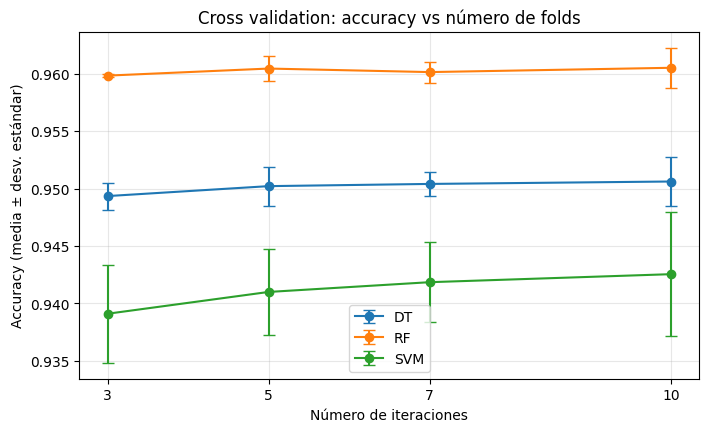

           DT      RF     SVM
folds                        
3      0.9494  0.9599  0.9391
5      0.9502  0.9605  0.9410
7      0.9504  0.9602  0.9419
10     0.9506  0.9605  0.9426

Número de folds elegido: 10


In [33]:
#@title 8. CROSS VALIDATION { display-mode: "form" }
from sklearn.model_selection import KFold, cross_val_score

ks = [3, 5, 7, 10]   # número de iteraciones (folds) a comparar
modelos_cv = {
    'DT':  (DecisionTreeClassifier(max_depth=mejor_prof, random_state=21), X_train, y_train),
    'RF':  (RandomForestClassifier(n_estimators=mejor_n, random_state=21), X_train, y_train),
    'SVM': (SVC(kernel=mejor_kernel), X_svm, y_svm),
}

tabla_cv = {}
plt.figure(figsize=(8, 4.5))
for nombre, (est, Xc, yc) in modelos_cv.items():
    medias, desvs = [], []
    for k in ks:
        s = cross_val_score(est, Xc, yc, cv=KFold(k, shuffle=True, random_state=21),
                            scoring='accuracy', n_jobs=-1)
        medias.append(s.mean())
        desvs.append(s.std())
    tabla_cv[nombre] = medias
    plt.errorbar(ks, medias, yerr=desvs, marker='o', capsize=4, label=nombre)

plt.title('Cross validation: accuracy vs número de folds')
plt.xlabel('Número de iteraciones')
plt.ylabel('Accuracy (media ± desv. estándar)')
plt.xticks(ks)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

tabla_cv = pd.DataFrame(tabla_cv, index=ks)
tabla_cv.index.name = 'folds'
print(tabla_cv.round(4))

k_mejor = int(tabla_cv.mean(axis=1).idxmax())
print("\nNúmero de folds elegido:", k_mejor)

#**Deep Learning**

In [34]:
#@title ARQUITECTURAS MLP { display-mode: "form" }
import tensorflow as tf
tf.keras.utils.set_random_seed(21)

# One-hot encoding de la salida
y_train_ohe = tf.keras.utils.to_categorical(y_train, num_classes=2)
y_test_ohe = tf.keras.utils.to_categorical(y_test, num_classes=2)

# Se separa 20% de train como validación para elegir los epochs
X_tr, X_val, y_tr_ohe, y_val_ohe = train_test_split(X_train_s, y_train_ohe, test_size=0.2, random_state=21)
print(X_tr.shape, X_val.shape, y_tr_ohe.shape, y_val_ohe.shape)

# input, 3 capas ocultas (64, 128, 128), output
def modelo_3_capas():
    return tf.keras.Sequential([
        tf.keras.layers.Flatten( input_shape= (X_train_s[0].shape)),
        tf.keras.layers.Dense(64, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(2, activation=tf.nn.softmax)
    ])

# input, 6 capas ocultas (64, 64, 128, 128, 256, 256), output
def modelo_6_capas():
    return tf.keras.Sequential([
        tf.keras.layers.Flatten( input_shape= (X_train_s[0].shape)),
        tf.keras.layers.Dense(64, activation=tf.nn.relu),
        tf.keras.layers.Dense(64, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(256, activation=tf.nn.relu),
        tf.keras.layers.Dense(256, activation=tf.nn.relu),
        tf.keras.layers.Dense(2, activation=tf.nn.softmax)
    ])

# input, 10 capas ocultas (todas de 128 neuronas), output
def modelo_10_capas():
    return tf.keras.Sequential([
        tf.keras.layers.Flatten( input_shape= (X_train_s[0].shape)),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),
        tf.keras.layers.Dense(2, activation=tf.nn.softmax)
    ])

arquitecturas = {
    'DL 3 capas': modelo_3_capas,
    'DL 6 capas': modelo_6_capas,
    'DL 10 capas': modelo_10_capas,
}

# Compilación
def compilar(model):
    model.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

for nombre, crear in arquitecturas.items():
    print(nombre)
    crear().summary()

(83123, 21) (20781, 21) (83123, 2) (20781, 2)
DL 3 capas


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,498 (103.51 KB)

 Trainable params: 26,498 (103.51 KB)

... (9 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 21)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │         2,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151,682 (592.51 KB)

 Trainable params: 151,682 (592.51 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
#@title  ENTRENAMIENTO FINAL Y TEST DE LOS MLP { display-mode: "form" }

for nombre, crear in arquitecturas.items():
    model = compilar(crear())
    model.fit(X_train_s, y_train_ohe, epochs=50, batch_size=100, verbose=0)

    # To test the model
    test_loss, test_acc = model.evaluate(X_test_s, y_test_ohe, verbose=0)
    print(nombre, '-> Test accuracy:', round(test_acc, 4), ' test_loss:', round(test_loss, 4))

    pred = model.predict(X_test_s, verbose=0).argmax(axis=1)
    resultados[nombre] = {'accuracy': test_acc,
                          'tpr': np.mean(pred[y_test == 1] == 1),
                          'tnr': np.mean(pred[y_test == 0] == 0)}

DL 3 capas -> Test accuracy: 0.9499  test_loss: 0.2024
DL 6 capas -> Test accuracy: 0.9532  test_loss: 0.1703
DL 10 capas -> Test accuracy: 0.9541  test_loss: 0.1751


#**Comparación final** — DT, RF, SVM y DL

             accuracy     tpr     tnr
RF             0.9612  0.9383  0.9787
DL 10 capas    0.9541  0.9368  0.9673
DT             0.9534  0.9376  0.9655
DL 6 capas     0.9532  0.9415  0.9622
DL 3 capas     0.9499  0.9490  0.9506
SVM            0.9440  0.9211  0.9616


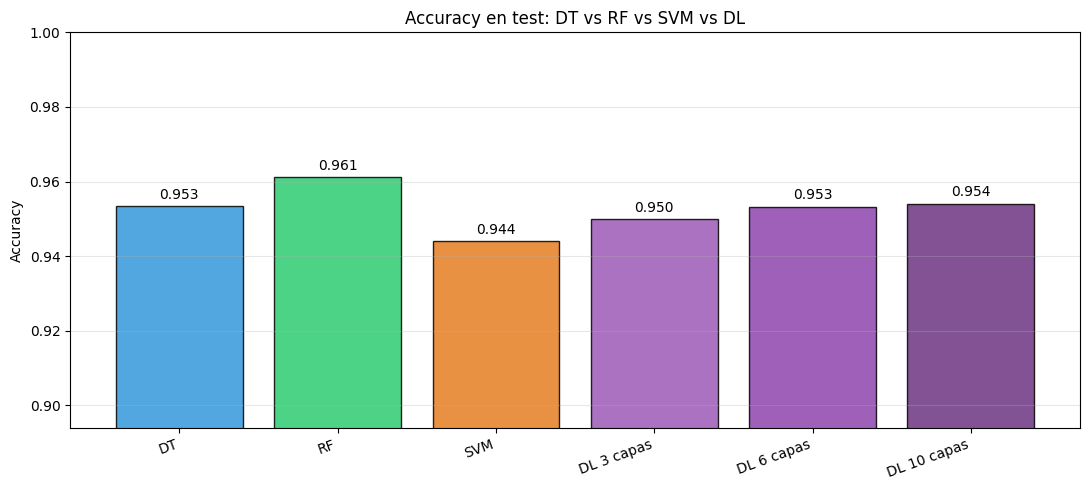

In [36]:
#@title  BARPLOT DE DESEMPEÑO { display-mode: "form" }
tabla_res = pd.DataFrame(resultados).T
print(tabla_res.sort_values('accuracy', ascending=False).round(4))

colores = ['#3498db', '#2ecc71', '#e67e22', '#9b59b6', '#8e44ad', '#6c3483']
plt.figure(figsize=(11, 5))
barras = plt.bar(tabla_res.index, tabla_res['accuracy'], color=colores[:len(tabla_res)],
                 edgecolor='black', alpha=0.85)
for b in barras:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.002,
             "%.3f" % b.get_height(), ha='center', fontsize=10)

plt.ylim(max(0, tabla_res['accuracy'].min() - 0.05), 1)
plt.title('Accuracy en test: DT vs RF vs SVM vs DL')
plt.ylabel('Accuracy')
plt.xticks(rotation=20, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#**Parte 3: Aprendizaje no supervisado (K-Means y DBSCAN)**

Se reutiliza el dataframe `df` ya limpio de la parte 2. En aprendizaje no supervisado el algoritmo no ve la variable `satisfaction`: solo se usan las 21 variables de entrada. `satisfaction` se usa únicamente para colorear la gráfica original y para comparar los resultados.

Flujo: escalar → K-Means → PCA a 2 componentes → DBSCAN (búsqueda de `eps` y `min_samples`) → tres gráficas (original, K-Means y DBSCAN).

In [37]:
#@title 1. ESCALAR LOS DATOS { display-mode: "form" }
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Solo las 21 variables de entrada
X_all = df.drop(columns='satisfaction').values
y_all = df['satisfaction'].values

# StandardScaler: z = (x - media) / desviación estándar  -> media 0 y varianza 1 en cada columna
X_scaled = StandardScaler().fit_transform(X_all)

print("X_scaled:", X_scaled.shape)
print("media (primeras 5 columnas):", X_scaled.mean(axis=0)[:5].round(3))
print("desv. estándar (primeras 5 columnas):", X_scaled.std(axis=0)[:5].round(3))

X_scaled: (129880, 21)
media (primeras 5 columnas): [-0. -0. -0. -0.  0.]
desv. estándar (primeras 5 columnas): [1. 1. 1. 1. 1.]


In [38]:
#@title 2. K-MEANS { display-mode: "form" }
from sklearn.cluster import KMeans

# n_clusters = número de clases de la base de datos (satisfaction: 0 y 1)
n_clases = len(np.unique(y_all))
print("n_clusters =", n_clases)

kmeans = KMeans(n_clusters=n_clases, n_init='auto', random_state=21)
kmeans.fit(X_scaled)

print("tamaño de cada cluster:", np.bincount(kmeans.labels_))
print("centroides:", kmeans.cluster_centers_.shape)      # (n_clusters, 21)

# ¿Qué tanto coinciden los clusters con las clases reales
tabla_km = pd.crosstab(y_all, kmeans.labels_, rownames=['satisfaction real'], colnames=['cluster K-Means'])
print(tabla_km)
print("pureza: %.3f" % (tabla_km.max(axis=0).sum() / len(y_all)))

n_clusters = 2
tamaño de cada cluster: [69172 60708]
centroides: (2, 21)
cluster K-Means        0      1
satisfaction real              
0                  21865  51587
1                  47307   9121
pureza: 0.761


In [39]:
#@title 3. PCA A 2 COMPONENTES { display-mode: "form" }
from sklearn.decomposition import PCA

pca = PCA(n_components=2, whiten=True)
X_pca = pca.fit_transform(X_scaled)

print('X_scaled: ', X_scaled.shape, ' X_pca: ', X_pca.shape)      # (n, 21) -> (n, 2)
print('varianza explicada por componente:', pca.explained_variance_ratio_.round(3))
print('varianza explicada total: %.3f' % pca.explained_variance_ratio_.sum())

X_scaled:  (129880, 21)  X_pca:  (129880, 2)
varianza explicada por componente: [0.186 0.113]
varianza explicada total: 0.300


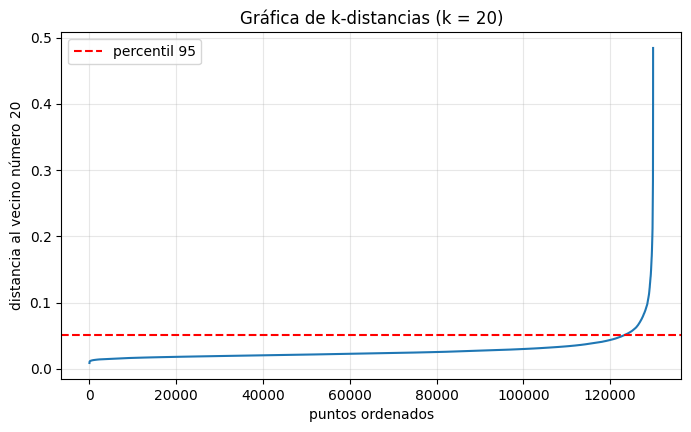

percentiles 50 / 90 / 95 / 99: [0.023 0.039 0.051 0.099]
 min_samples  eps  clusters  ruido %  cluster más grande %
          10 0.02       430     14.6                  68.4
          10 0.03       106      4.7                  93.6
          10 0.05        32      1.3                  98.2
          10 0.08        10      0.4                  99.5
          10 0.12         4      0.1                  99.9
          20 0.02       480     48.8                  14.5
          20 0.03        97     13.2                  74.5
          20 0.05        17      3.2                  96.4
          20 0.08         6      1.0                  98.9
          20 0.12         3      0.3                  99.7
          50 0.02         6     99.7                   0.1
          50 0.03       132     65.7                   9.3
          50 0.05        19     11.7                  87.1
          50 0.08         2      3.1                  96.8
          50 0.12         1      1.0                  99.0

In [40]:
#@title 4a. DBSCAN: BÚSQUEDA DE eps Y min_samples { display-mode: "form" }
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# 1) Gráfica de k-distancias: distancia de cada punto a su vecino número k (k = min_samples), ordenada.
#    El "codo" de la curva sugiere eps: antes del codo están los puntos de zonas densas, después el ruido.
k = 20
dist, _ = NearestNeighbors(n_neighbors=k).fit(X_pca).kneighbors(X_pca)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(kdist)
plt.axhline(np.percentile(kdist, 95), color='red', linestyle='--', label='percentil 95')
plt.xlabel('puntos ordenados')
plt.ylabel('distancia al vecino número %d' % k)
plt.title('Gráfica de k-distancias (k = %d)' % k)
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print('percentiles 50 / 90 / 95 / 99:', np.percentile(kdist, [50, 90, 95, 99]).round(3))

# 2) Pruebas con varios valores (como el bucle del método del codo en K-Means)
filas = []
for ms in [10, 20, 50]:
    for eps in [0.02, 0.03, 0.05, 0.08, 0.12]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit(X_pca).labels_
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        filas.append({'min_samples': ms,
                      'eps': eps,
                      'clusters': n_cl,
                      'ruido %': round((lab == -1).mean() * 100, 1),
                      'cluster más grande %': round(np.bincount(lab[lab >= 0]).max() / len(lab) * 100, 1) if n_cl > 0 else 0})
tabla_dbscan = pd.DataFrame(filas)
print(tabla_dbscan.to_string(index=False))

**Por qué `eps = 0.05` y `min_samples = 20`**

- DBSCAN se aplica sobre los 2 componentes de PCA, porque en las 21 dimensiones la distancia pierde sentido y calcular vecindades con ~130.000 filas sería muy costoso. Con `whiten=True` cada componente tiene varianza 1, así que `eps` mide lo mismo en ambos ejes.
- `min_samples`: en 2 dimensiones la regla práctica es al menos 2 × dimensiones = 4. Como la base es muy grande se usó un valor mayor (20), para que un cluster exija una vecindad realmente densa y no se formen clusters con unos pocos puntos casuales.
- `eps`: se tomó del codo de la gráfica de k-distancias con k = `min_samples` = 20. La curva es casi plana hasta el percentil 90 (≈ 0.04) y sube rápido después (percentil 95 ≈ 0.05, percentil 99 ≈ 0.10). Si `eps` es menor, DBSCAN declara demasiado ruido (con 0.03 y 20 puntos, 13 % de ruido; con 0.02, 49 %). Si es mayor, todo se une en un solo cluster (con 0.12 solo quedan 3 clusters y 0.3 % de ruido).
- Resultado con (0.05, 20): 17 clusters, 3.2 % de ruido y un cluster que concentra cerca del 96 % de los puntos.
- Lectura: los datos forman una nube continua y densa en el plano de PCA (los 2 componentes solo conservan alrededor del 30 % de la varianza). Por eso DBSCAN encuentra un cluster grande, algunos grupos pequeños y ruido en los bordes, y no separa pasajeros satisfechos de insatisfechos.

In [41]:
#@title 4b. DBSCAN FINAL { display-mode: "form" }
EPS = 0.05          # valor elegido (justificación en la celda de texto de arriba)
MIN_SAMPLES = 20    # valor elegido

DBS = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
DBS.fit(X_pca)

etiquetas_db = DBS.labels_
n_clusters_db = len(set(etiquetas_db)) - (1 if -1 in etiquetas_db else 0)
print('clusters encontrados:', n_clusters_db)
print('puntos de ruido (etiqueta -1): %d (%.1f %%)' % ((etiquetas_db == -1).sum(), (etiquetas_db == -1).mean() * 100))
print('tamaño de cada cluster:', np.bincount(etiquetas_db[etiquetas_db >= 0]))

clusters encontrados: 17
puntos de ruido (etiqueta -1): 4113 (3.2 %)
tamaño de cada cluster: [125208    110     70     48     37     21     36     24     37     23
     20     30     15     18     30     20     20]


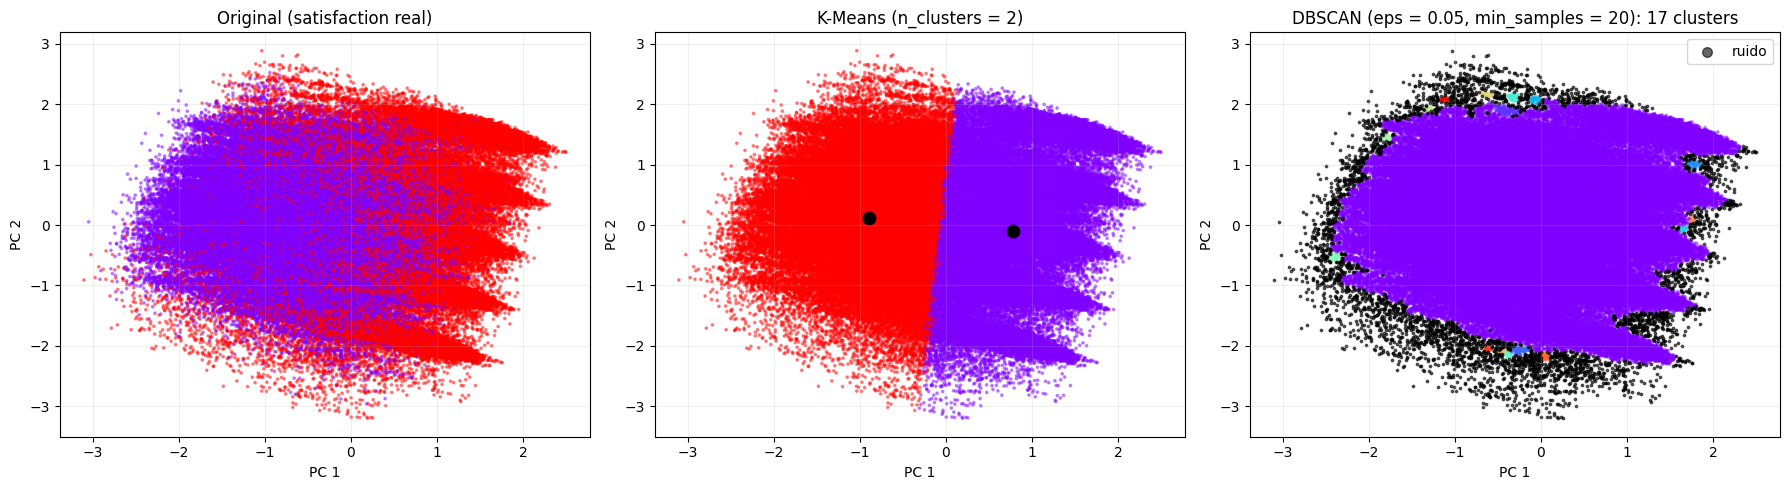

In [42]:
#@title 5. GRÁFICAS: ORIGINAL, K-MEANS Y DBSCAN { display-mode: "form" }
# Los centroides de K-Means (21 dimensiones) se proyectan al mismo plano de PCA para dibujarlos
centros_2d = pca.transform(kmeans.cluster_centers_)
ruido = etiquetas_db == -1

plt.figure(figsize=(18, 5))

plt.subplot(131)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_all, cmap='rainbow', s=3, alpha=0.4)
plt.title('Original (satisfaction real)')
plt.xlabel('PC 1'); plt.ylabel('PC 2')
plt.grid(alpha=0.2)

plt.subplot(132)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans.labels_, cmap='rainbow', s=3, alpha=0.4)
plt.scatter(centros_2d[:, 0], centros_2d[:, 1], color='black', s=80)
plt.title('K-Means (n_clusters = %d)' % n_clases)
plt.xlabel('PC 1'); plt.ylabel('PC 2')
plt.grid(alpha=0.2)

plt.subplot(133)
plt.scatter(X_pca[~ruido, 0], X_pca[~ruido, 1], c=etiquetas_db[~ruido], cmap='rainbow', s=3, alpha=0.4)
plt.scatter(X_pca[ruido, 0], X_pca[ruido, 1], color='black', s=3, alpha=0.6, label='ruido')
plt.title('DBSCAN (eps = %s, min_samples = %d): %d clusters' % (EPS, MIN_SAMPLES, n_clusters_db))
plt.xlabel('PC 1'); plt.ylabel('PC 2')
plt.legend(markerscale=4)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()